# 01 - Data Exploration — HAM10000

Before writing a single line of model code, we need to understand the data:
how many images, how the 7 lesion classes are distributed, what the images
look like, and what the patient metadata tells us. Good exploration is what
lets us make informed choices later (how to split, how to fight imbalance,
what augmentation is safe).

**Prerequisite.** Run `python prepare_data.py` first (after placing the
Kaggle download in `data/raw/`). That builds `data/processed/metadata_splits.csv`
with a leakage-safe `split` column, which we load here.

In [ ]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import yaml
CFG = yaml.safe_load(Path("config.yaml").read_text())
IMAGES_DIR = Path(CFG["data"]["raw_dir"]) / "images"
SPLITS_CSV = CFG["data"]["splits_csv"]
print("project root:", ROOT)


project root: /home/aproia/AML-HAM10000


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from src.dataset import CLASSES, CLASS_FULLNAME

sns.set_theme(style="whitegrid")
df = pd.read_csv(SPLITS_CSV)
print(df.shape)
df.head()

(10015, 8)


,lesion_id,image_id,dx,dx_type,age,sex,localization,split
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,val
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,val
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,train
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,train
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,train


## 1. Class distribution

The most important fact about HAM10000 is that it is **severely
imbalanced**. Let's quantify it.

dx
akiec     327
bcc       514
bkl      1099
df        115
mel      1113
nv       6705
vasc      142
Name: count, dtype: int64


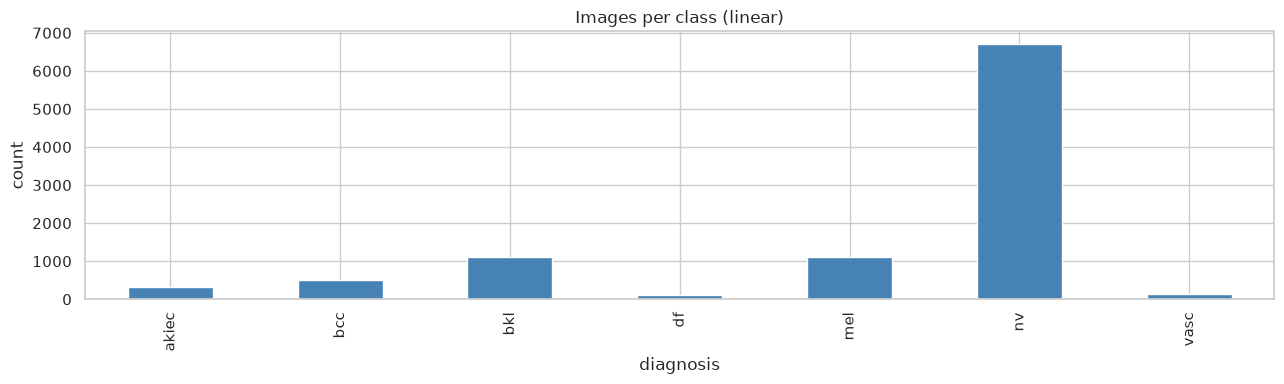

In [3]:
counts = df["dx"].value_counts().reindex(CLASSES)
print(counts)

fig = plt.figure(figsize=(13, 4))
ax = counts.plot(kind="bar", color="steelblue")
ax.set(title="Images per class (linear)", xlabel="diagnosis", ylabel="count")
plt.tight_layout()
fig.savefig("figures/class_distribution.png", dpi=120)
plt.show()

`nv` (melanocytic nevi) dominates at ~67% while `df`
(dermatofibroma) has ~1%. A classifier that always predicts `nv` would
already score ~67% accuracy while being clinically useless. This is why,
from here on, we track **balanced accuracy** and **macro-F1** instead of
raw accuracy, and why we compare imbalance-handling strategies later.

## 2. What do the images look like?

We plot a grid of random samples per class to identify artifacts or specific details between classes.

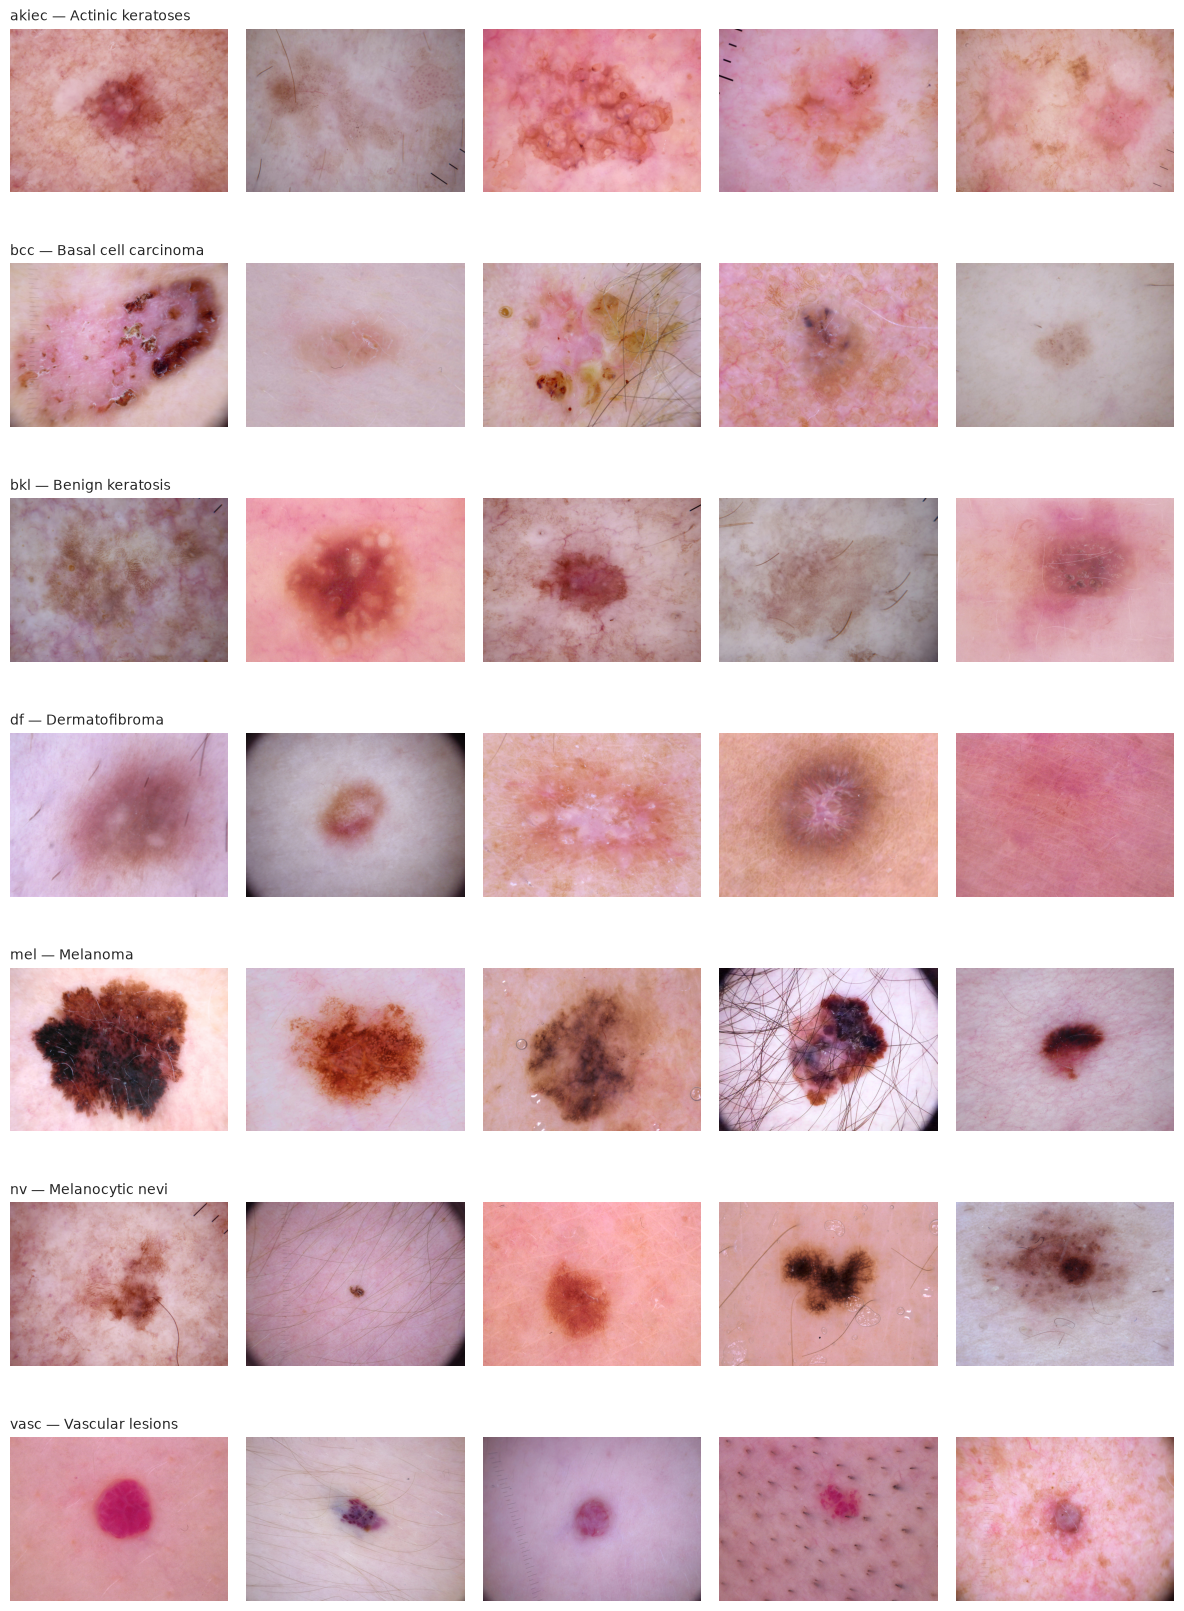

In [4]:
fig, axes = plt.subplots(len(CLASSES), 5, figsize=(12, 2.4 * len(CLASSES)))
rng = np.random.default_rng(0)

# add class name on each row (leftmost subplot of the row)
for r, cls in enumerate(CLASSES):
    axes[r, 0].set_title(f"{cls} — {CLASS_FULLNAME[cls]}", loc="left", fontsize=10)
for r, cls in enumerate(CLASSES):
    ids = df[df.dx == cls]["image_id"].to_numpy()
    for c in range(5):
        ax = axes[r, c]
        img = Image.open(IMAGES_DIR / f"{rng.choice(ids)}.jpg")
        ax.imshow(img); ax.axis("off")
        if c == 0:
            ax.set_ylabel(f"{cls}\n{CLASS_FULLNAME[cls]}", rotation=0,
                          ha="right", va="center", fontsize=9)
plt.tight_layout(); plt.savefig("figures/sample_grid.png", dpi=110); plt.show()

## 3. Patient metadata

HAM10000 ships age, sex and lesion localization per image. We keep the
model **images-only**, but the metadata is worth understanding, it can
reveal sampling biases (e.g. certain classes concentrated in certain body
sites) and it has missing values we should be aware of.

missing values:
 age             57
sex              0
localization     0
dtype: int64 



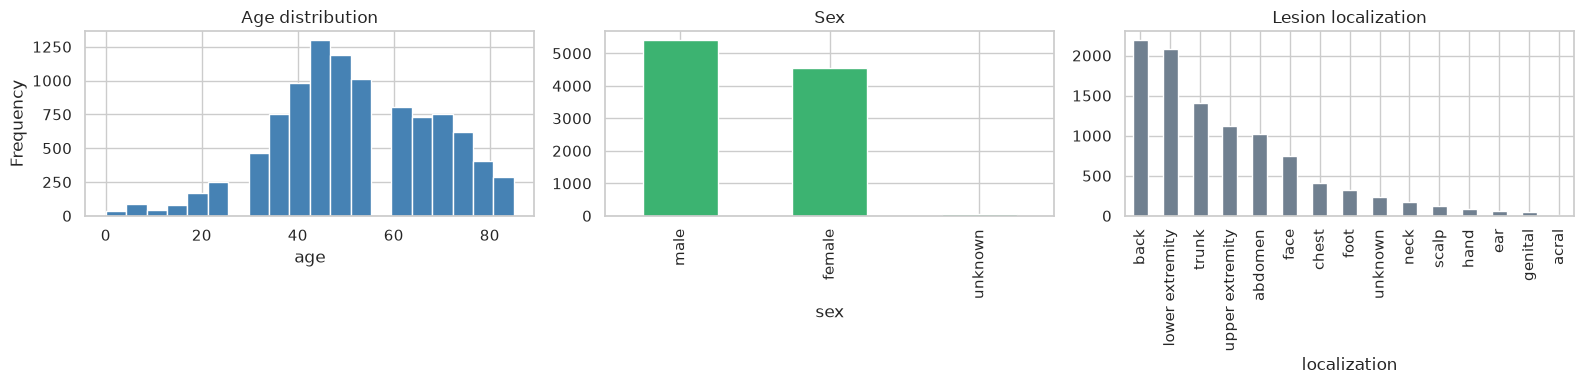

In [5]:
print("missing values:\n", df[["age", "sex", "localization"]].isna().sum(), "\n")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df["age"].dropna().plot.hist(bins=20, ax=ax[0], color="steelblue")
ax[0].set_title("Age distribution"); ax[0].set_xlabel("age")
df["sex"].value_counts().plot.bar(ax=ax[1], color="mediumseagreen")
ax[1].set_title("Sex")
df["localization"].value_counts().plot.bar(ax=ax[2], color="slategray")
ax[2].set_title("Lesion localization")
plt.tight_layout(); plt.savefig("figures/metadata.png", dpi=120); plt.show()

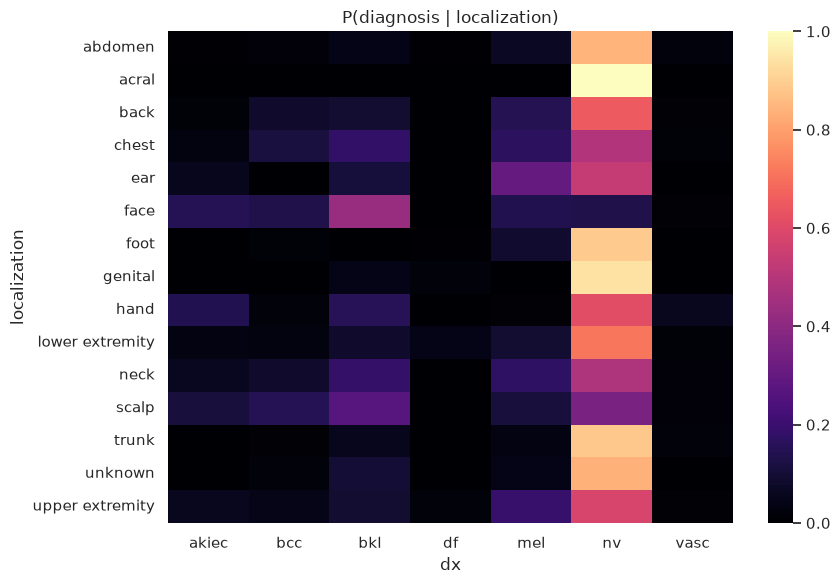

In [6]:
# Does diagnosis correlate with body site? (row-normalized heatmap)
ct = pd.crosstab(df["localization"], df["dx"], normalize="index").reindex(columns=CLASSES)
plt.figure(figsize=(9, 6))
sns.heatmap(ct, annot=False, cmap="magma")
plt.title("P(diagnosis | localization)"); plt.tight_layout()
plt.savefig("figures/dx_by_localization.png", dpi=120); plt.show()

## 4. The split: why we group by `lesion_id`

HAM10000 has 10,015 images but **fewer distinct lesions**, many of them
were photographed multiple times. Two photos of the same lesion are
near-duplicates. If one lands in *train* and its twin in *test*, the test
score is inflated: the model has effectively seen the test image.

`prepare_data.py` prevents it by assigning each lesion (not each image)
to a single split.

In [7]:
imgs_per_lesion = df.groupby("lesion_id").size()
print(f"distinct lesions: {df.lesion_id.nunique()}  vs images: {len(df)}")
print(f"lesions photographed more than once: {(imgs_per_lesion > 1).sum()}")
print(f"max images of one lesion: {imgs_per_lesion.max()}")

# The leakage guard: every lesion must live in exactly one split.
crossing = df.groupby("lesion_id")["split"].nunique()
print("\nlesions crossing split boundaries:", int((crossing > 1).sum()), "(must be 0)")

print("\nimages per split:\n", df["split"].value_counts())
print("\nclass proportions per split (%):")
prop = pd.crosstab(df["split"], df["dx"], normalize="index")[CLASSES] * 100
display(prop.round(1))

distinct lesions: 7470  vs images: 10015
lesions photographed more than once: 1956
max images of one lesion: 6

lesions crossing split boundaries: 0 (must be 0)

images per split:
 split
train    7002
val      1532
test     1481
Name: count, dtype: int64

class proportions per split (%):


dx,akiec,bcc,bkl,df,mel,nv,vasc
split,,,,,,,
test,3.1,4.8,11.3,1.4,11.1,67.0,1.3
train,3.3,5.2,11.1,1.1,11.1,66.8,1.4
val,3.3,5.0,10.2,1.2,11.1,67.5,1.6


Zero lesions cross the boundary, and class proportions
are similar across train/val/test (stratified split), so our validation
and test numbers will be trustworthy.

## 5. Normalization statistics

Neural nets train best on normalized inputs. For a pretrained ImageNet
backbone we reuse ImageNet's mean/std; if you train the CNN from scratch,
the *train-split* statistics below are more appropriate. Copy them into
`config.yaml` → `data.normalization` if you go that route.

In [8]:
from torchvision import transforms
import torch

train_ids = df[df.split == "train"]["image_id"].to_numpy()
rng = np.random.default_rng(0)
sample = rng.choice(train_ids, size=min(800, len(train_ids)), replace=False)
to_tensor = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor()])

acc = torch.zeros(3); acc_sq = torch.zeros(3); n = 0
for iid in sample:
    x = to_tensor(Image.open(IMAGES_DIR / f"{iid}.jpg").convert("RGB"))
    acc += x.mean(dim=(1, 2)); acc_sq += (x ** 2).mean(dim=(1, 2)); n += 1
mean = acc / n
std = (acc_sq / n - mean ** 2).sqrt()
print("train mean:", [round(float(v), 4) for v in mean])
print("train std :", [round(float(v), 4) for v in std])

train mean: [0.7636, 0.5442, 0.5683]
train std : [0.1421, 0.1546, 0.1715]
